Question 1

In [5]:
from pathlib import Path
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter

In [12]:
# ---------- Load image ----------
im = cv.imread('a2images/a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
# ---------- Parameters ----------
sigma_min = 4
sigma_max = 30
n_scales  = 20
sigmas = np.geomspace(sigma_min, sigma_max, n_scales)   # geometric progression of sigma
thresh = 0.15          # response threshold (tune this)
overlap_thresh = 0.5   # for pruning overlapping circles

In [13]:
# ---------- Build scale-normalised LoG scale space ----------
def log_kernel(sigma):
    """Scale-normalised Laplacian of Gaussian kernel (sigma^2 * LoG)."""
    size = int(2 * np.ceil(3 * sigma) + 1)
    ax = np.arange(-(size // 2), size // 2 + 1)
    xx, yy = np.meshgrid(ax, ax)
    r2 = xx**2 + yy**2
    g = np.exp(-r2 / (2 * sigma**2)) / (2 * np.pi * sigma**2)
    log = ((r2 - 2 * sigma**2) / sigma**4) * g
    return (sigma**2 * log).astype(np.float32)

h, w = gray.shape
scale_space = np.zeros((h, w, len(sigmas)), dtype=np.float32)

for i, s in enumerate(sigmas):
    # negative sign so bright blobs on darker background give positive peaks
    scale_space[:, :, i] = -cv.filter2D(gray, -1, log_kernel(s),
                                        borderType=cv.BORDER_REPLICATE)


In [14]:
# ---------- Scale-space extrema detection (3x3x3 neighbourhood) ----------
local_max = maximum_filter(scale_space, size=(3, 3, 3))
mask = (scale_space == local_max) & (scale_space > thresh)
ys, xs, ss = np.nonzero(mask)

blobs = []
for y, x, si in zip(ys, xs, ss):
    sigma = sigmas[si]
    r = np.sqrt(2) * sigma              # radius of blob for a circle
    blobs.append((x, y, r, sigma, scale_space[y, x, si]))

In [15]:
# ---------- Prune overlapping circles (keep stronger response) ----------
def overlap(b1, b2):
    d = np.hypot(b1[0] - b2[0], b1[1] - b2[1])
    r1, r2 = b1[2], b2[2]
    if d >= r1 + r2:
        return 0.0
    if d <= abs(r1 - r2):
        return 1.0
    # approximate overlap fraction using distance
    return (r1 + r2 - d) / (2 * min(r1, r2))

blobs.sort(key=lambda b: -b[4])
kept = []
for b in blobs:
    if all(overlap(b, k) < overlap_thresh for k in kept):
        kept.append(b)

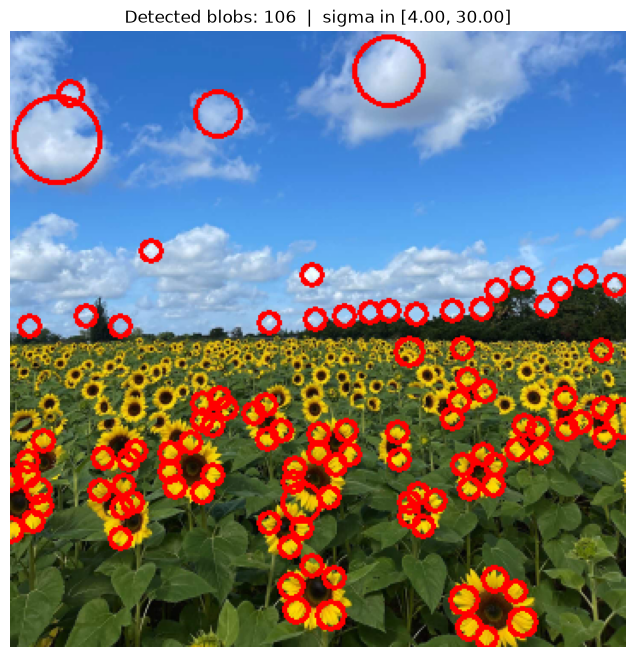

Number of circles detected : 106
Sigma range used           : 4.00 to 30.00  (20 scales)

Largest circles (x, y, radius, sigma):
  centre = (27, 63),  radius = 24.97 px,  sigma = 17.65,  response = 0.176
  centre = (221, 23),  radius = 20.20 px,  sigma = 14.28,  response = 0.162
  centre = (121, 48),  radius = 13.21 px,  sigma = 9.34,  response = 0.159
  centre = (170, 275),  radius = 10.69 px,  sigma = 7.56,  response = 0.173
  centre = (359, 226),  radius = 10.69 px,  sigma = 7.56,  response = 0.157


In [16]:
# ---------- Draw circles ----------
out = im.copy()
for x, y, r, s, resp in kept:
    cv.circle(out, (int(x), int(y)), int(round(r)), (0, 0, 255), 2)

plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(out, cv.COLOR_BGR2RGB))
plt.title(f'Detected blobs: {len(kept)}  |  sigma in [{sigmas[0]:.2f}, {sigmas[-1]:.2f}]')
plt.axis('off')
plt.show()

# ---------- Report ----------
print(f"Number of circles detected : {len(kept)}")
print(f"Sigma range used           : {sigmas[0]:.2f} to {sigmas[-1]:.2f}  ({n_scales} scales)")

kept_by_radius = sorted(kept, key=lambda b: -b[2])
print("\nLargest circles (x, y, radius, sigma):")
for x, y, r, s, resp in kept_by_radius[:5]:
    print(f"  centre = ({x}, {y}),  radius = {r:.2f} px,  sigma = {s:.2f},  response = {resp:.3f}")